In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [30]:
df=pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Data loaded successfully!")

Data loaded successfully!


In [31]:
df.head()
df.shape
df.info()
df["Churn"].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [32]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


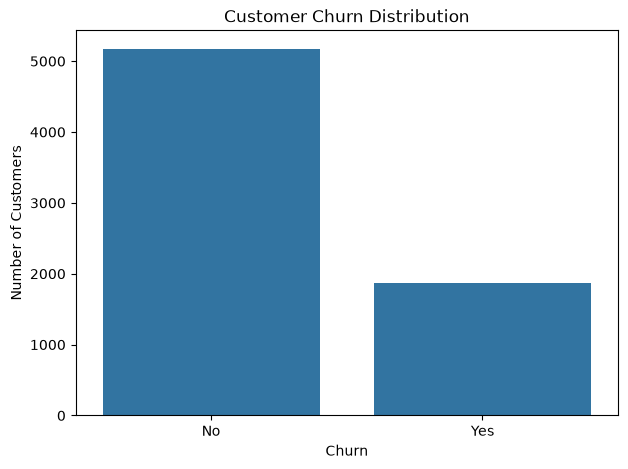

In [33]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

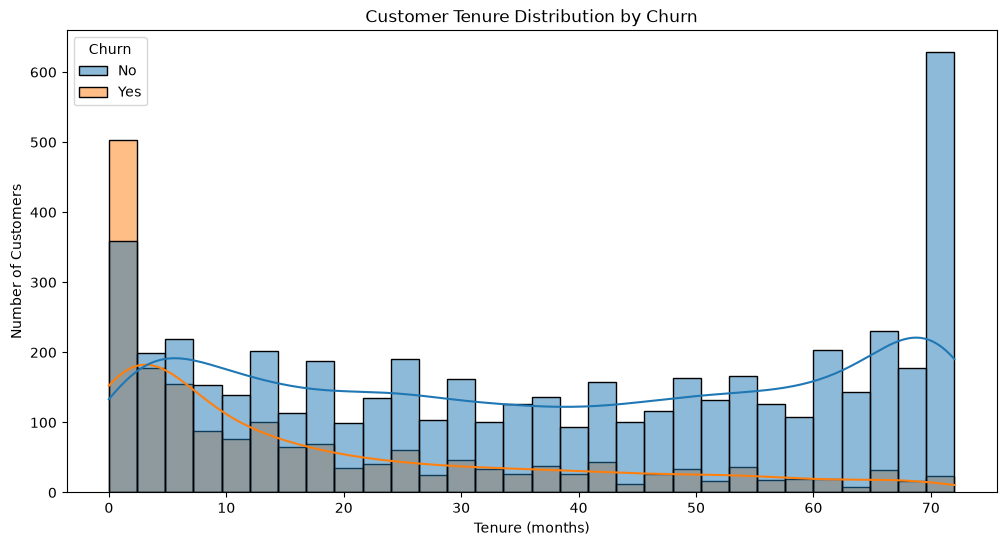

In [34]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df,x="tenure",hue="Churn",bins=30,kde=True)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of Customers")

plt.show()

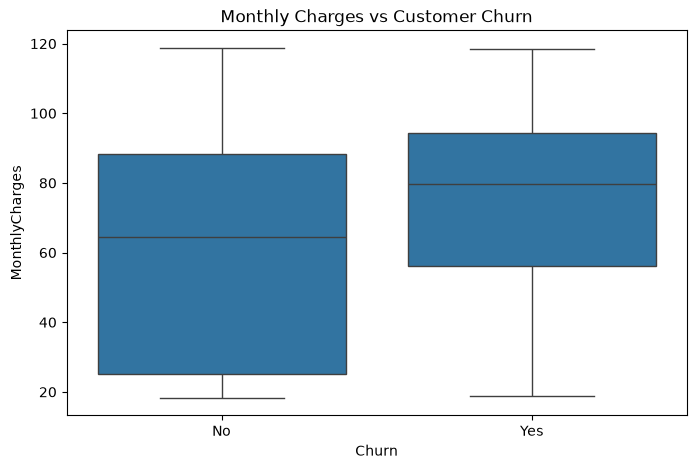

In [35]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")

plt.show()

In [36]:
print(df["TotalCharges"].head(10))
print("Data type:", df["TotalCharges"].dtype)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str
Data type: str


In [37]:
print("Blank values:", (df["TotalCharges"].str.strip() == "").sum())

Blank values: 11


In [38]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [39]:
print("New data type:", df["TotalCharges"].dtype)

print("Missing values:", df["TotalCharges"].isnull().sum())

New data type: float64
Missing values: 11


In [40]:
median_value=df["TotalCharges"].median()
print("Median TotalCharges:", median_value)

Median TotalCharges: 1397.475


In [41]:
df["TotalCharges"] = df["TotalCharges"].fillna(median_value)

In [42]:
print("Missing values after cleaning:",df["TotalCharges"].isnull().sum())

Missing values after cleaning: 0


In [43]:
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 0


In [44]:
df=df.drop("customerID",axis=1)

In [45]:
X=df.drop("Churn",axis=1)
y=df["Churn"]

In [46]:
print("X shape:",X.shape)
print("y shape:",y.shape)
print("feature columns:")
print(X.columns.tolist())

X shape: (7043, 19)
y shape: (7043,)
feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [47]:
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns

categorical_cols = X.select_dtypes(include=["object", "str"]).columns

print("Numerical columns:", list(numerical_cols))

print("\nCategorical columns:", list(categorical_cols))

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
